# ARM RULE DISCOVERY — Phân tích luật qua Train → Validation → Test

Chạy sau `arm_test.ipynb`. Notebook này đọc luật đã khóa và đánh giá, không fit hoặc chọn
lại cấu hình. Kiểm tra **support, confidence và lift** ở cả ba tập, sau đó khám phá độ dài,
số lần xuất hiện, external/Gold-only, khác biệt horizon và các luật nổi bật.

Một luật được tính riêng tại từng horizon. Các luật có thể chồng lấn; số luật không phải
số bằng chứng độc lập. Xếp hạng bằng Test chỉ mô tả hậu kiểm, không phải lựa chọn được
kiểm chứng trên một tập chưa xem. Ngưỡng encoding fit riêng từng Train.

## 1. Đọc dữ liệu và kiểm tra phạm vi

In [1]:
from pathlib import Path
import json
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm gốc dự án từ thư mục hiện tại để chạy local không cần sửa đường dẫn.
current = Path.cwd().resolve()
ROOT = next(path for path in [current, *current.parents]
            if (path / 'project_manifest.json').exists())
result_dir = ROOT / 'results/arm'
horizons = [1, 5, 10, 20]
rules = pd.concat([pd.read_csv(result_dir/f'3_test/H{h}_evaluated_rules.csv')
                   for h in horizons],ignore_index=True)
selected = pd.read_csv(result_dir/'2_validation/H1_selected_rules.csv')
config = selected.iloc[0][['min_support','min_confidence','min_lift']].to_dict()
summary_rows = []
for (h,direction), group in rules.groupby(['Horizon','Direction']):
    for category in ['All','External','Gold_only']:
        part = group if category == 'All' else group.loc[group.External.eq(category=='External')]
        summary_rows.append({'Horizon':h,'Direction':direction,'Category':category,
            'Rules':len(part),'Median_Val_Lift':part.Val_Lift.median(),
            'Median_Test_Lift':part.Test_Lift.median(),
            'Test_Lift_Above_1_Count':int(part.Test_Lift.gt(1).sum()),
            'Test_Enough_And_Lift_Above_1_Count':int((part.Test_Lift.gt(1)&part.Test_Antecedent_Count.ge(30)).sum()),
            'Test_Base_Rate':group.Test_Base_Rate.iloc[0]})
summary = pd.DataFrame(summary_rows)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
horizon_colors = ['#2878a5', '#e49a38', '#579a71', '#8c6bb1']
pd.set_option('display.max_colwidth', 100)

print('Cấu hình Apriori chung đã khóa trước Test:')
display(pd.DataFrame([{key: config[key] for key in
                      ['min_support', 'min_confidence', 'min_lift']}]))
print('Kết quả kiểm chứng và số mẫu từng horizon:')
display(pd.read_csv(result_dir/'3_test/summary.csv'))
print(f'Tổng lượt luật đã chốt: {len(rules):,}')
print(f'Số antecedent + hướng khác nhau: {rules.Rule_ID.nunique():,}')
if rules.duplicated(['Horizon', 'Rule_ID']).any():
    raise ValueError('Có luật trùng trong cùng horizon; cần kiểm tra trước khi thống kê.')
if not rules.Test_Rows.eq(683).all():
    raise ValueError('Số phiên Test không nhất quán.')
print('Không có luật trùng trong cùng horizon; Test đều có 683 phiên.')

Cấu hình Apriori chung đã khóa trước Test:


,min_support,min_confidence,min_lift
0,0.02,0.5,1.0


Kết quả kiểm chứng và số mẫu từng horizon:


,Horizon,Train_Candidate_Rules,Validation_Selected_Rules,Test_Evaluated_Rules,Test_Lift_Above_1_At_Least_30,Test_Lift_Above_1_Fewer_Than_30,Test_Lift_At_Most_1,Test_Undefined_Lift,Median_Test_Support,Median_Test_Confidence,Median_Test_Lift
0,1,4374,835,835,449,70,311,5,0.054173,0.546589,1.032188
1,5,4341,476,476,261,49,166,0,0.058565,0.638653,1.044986
2,10,4328,442,442,181,55,197,9,0.053441,0.612903,1.011506
3,20,4335,536,536,151,64,316,5,0.046852,0.626667,0.957006


Tổng lượt luật đã chốt: 2,289
Số antecedent + hướng khác nhau: 1,384
Không có luật trùng trong cùng horizon; Test đều có 683 phiên.


In [2]:
# Đếm các giai đoạn riêng biệt: itemsets không đồng nghĩa với rules.
overview_rows = []
itemset_tables = []
for h in horizons:
    folder = result_dir / f'ARM-H{h}'
    state = pickle.loads((ROOT/f'data/arm/ARM-H{h}/train_encoding.pkl').read_bytes())
    # Counts saved during Apriori; no need to persist every intermediate itemset.
    itemsets = pd.DataFrame({'Size':[size for size,count in state['itemset_counts'].items() for _ in range(count)]})
    candidates = pd.read_csv(result_dir/f'1_train/H{h}_rules.csv')
    selected = rules.loc[rules.Horizon.eq(h)]
    itemsets['Horizon'] = h
    itemset_tables.append(itemsets)
    overview_rows.append({'Horizon': f'H{h}', 'Frequent_itemsets': len(itemsets),
                          'Candidate_rules': len(candidates), 'Locked_rules': len(selected),
                          'External_rules': int(selected.External.sum()),
                          'Gold_only_rules': int((~selected.External).sum())})
overview = pd.DataFrame(overview_rows)
itemsets_all = pd.concat(itemset_tables, ignore_index=True)
print('Tổng quan quá trình: frequent itemsets → luật ứng viên → luật đã chốt:')
display(overview)

Tổng quan quá trình: frequent itemsets → luật ứng viên → luật đã chốt:

,Horizon,Frequent_itemsets,Candidate_rules,Locked_rules,External_rules,Gold_only_rules
0,H1,14115,4374,835,649,186
1,H5,14078,4341,476,366,110
2,H10,14061,4328,442,323,119
3,H20,14056,4335,536,405,131


## Kiểm tra ba khía cạnh: Support, Confidence, Lift

- **Support:** tỷ lệ phiên A và C cùng xảy ra; cho biết luật bao phủ bao nhiêu trường hợp joint.
- **Confidence:** tỷ lệ C đúng khi A xảy ra; luôn đọc cùng tỷ lệ lớp nền của tập tương ứng.
- **Lift:** confidence chia tỷ lệ lớp nền; >1 là liên hệ dương so với base rate, không phải
  kiểm định ý nghĩa thống kê.

So cùng các luật đã khóa qua Train/Val/Test, không loại luật yếu trên Test. Median dưới
đây bỏ NaN khi không tính được chỉ số. Không đặt thêm ngưỡng support/confidence trên Test.

Median support, confidence, lift của cùng bộ luật qua ba tập:


Train_Support  Train_Confidence  Train_Lift  Val_Support  \
Horizon Direction                                                             
1       NonUp             0.0425            0.5172      1.0841       0.0452   
        Up                0.0516            0.5418      1.0361       0.0637   
5       NonUp             0.0371            0.5132      1.1450       0.0347   
        Up                0.0534            0.5721      1.0368       0.0641   
10      NonUp             0.0328            0.5152      1.1615       0.0376   
        Up                0.0539            0.5769      1.0367       0.0632   
20      NonUp             0.0310            0.5163      1.1547       0.0422   
        Up                0.0545            0.5847      1.0577       0.0627   

                   Val_Confidence  Val_Lift  Test_Support  Test_Confidence  \
Horizon Direction                                                            
1       NonUp              0.5294    1.1012        0.0469           0.4545   
        Up                 0.5567    1.0720        0.0571           0.5778   
5       NonUp              0.4923    1.0626        0.0264           0.3644   
        Up                 0.5672    1.0567        0.0644           0.6498   
10      NonUp              0.5288    1.0989        0.0307           0.3572   
        Up                 0.5579    1.0754        0.0586           0.6239   
20      NonUp              0.5487    1.1441        0.0264           0.3137   
        Up                 0.5672    1.0898        0.0512           0.6418   

                   Test_Lift  
Horizon Direction             
1       NonUp         1.0383  
        Up            1.0277  
5       NonUp         0.9535  
        Up            1.0517  
10      NonUp         0.9206  
        Up            1.0195  
20      NonUp         0.9481  
        Up            0.9592

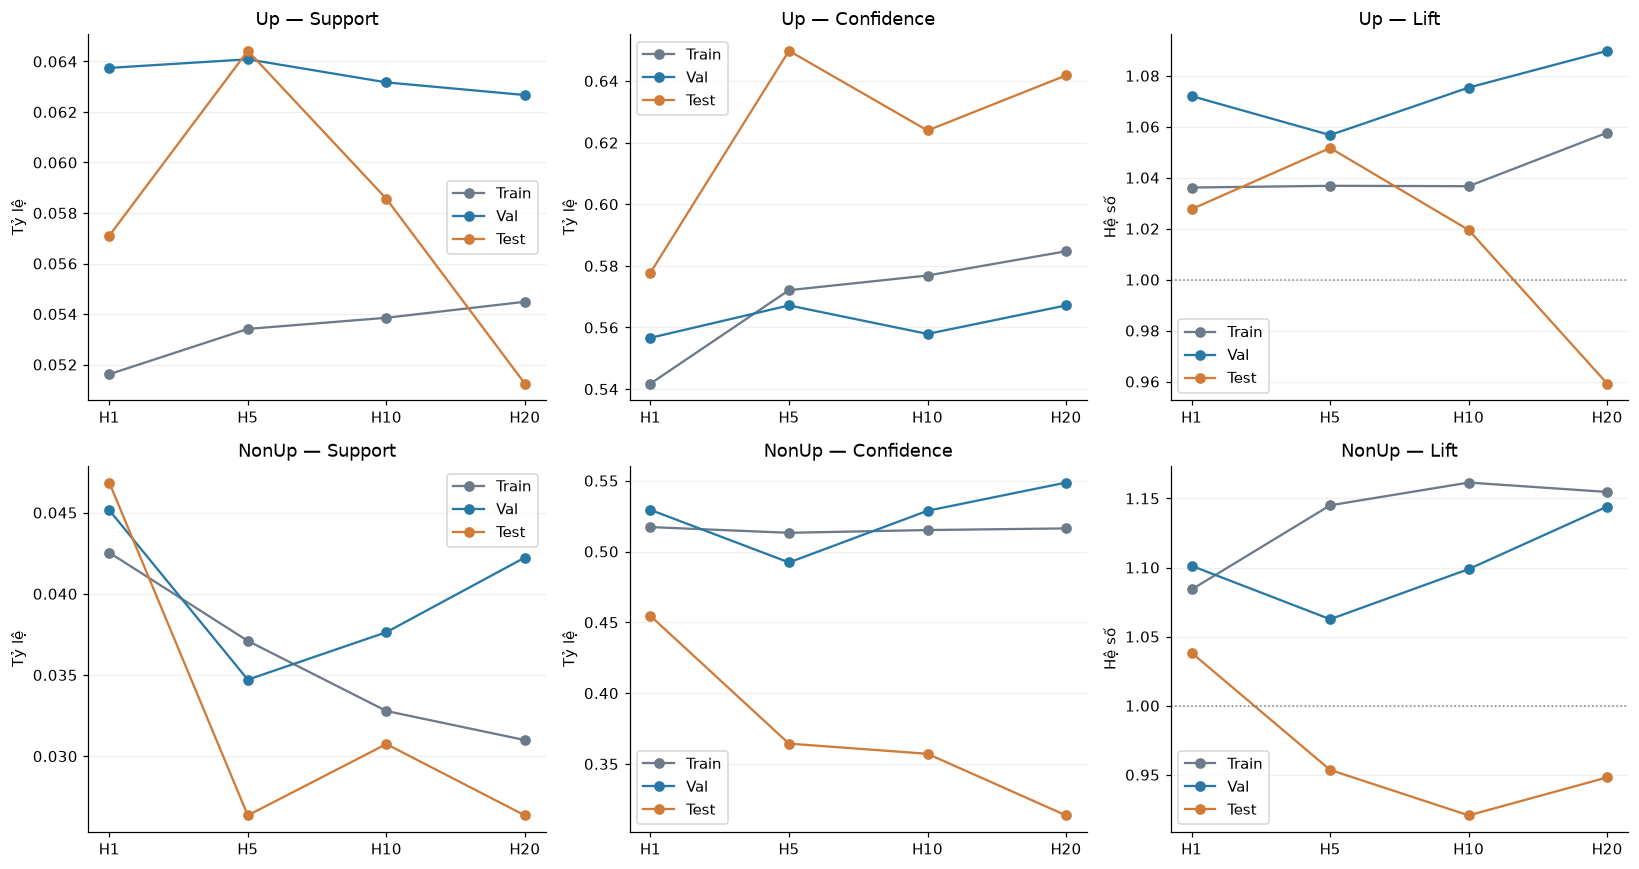

Val được dùng chọn luật, nên độ mạnh trên Val không phải bằng chứng độc lập.


In [3]:
metric_columns = [f'{split}_{metric}' for split in ['Train','Val','Test']
                  for metric in ['Support','Confidence','Lift']]
three_metrics = rules.groupby(['Horizon','Direction'])[metric_columns].median()
print('Median support, confidence, lift của cùng bộ luật qua ba tập:')
display(three_metrics.round(4))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, direction in enumerate(['Up','NonUp']):
    group = three_metrics.xs(direction, level='Direction').reindex(horizons)
    for col, metric in enumerate(['Support','Confidence','Lift']):
        ax = axes[row,col]
        for split, color in [('Train','#6d7a89'),('Val','#2878a5'),('Test','#d07b38')]:
            ax.plot(range(4), group[f'{split}_{metric}'], 'o-', color=color, label=split)
        if metric == 'Lift':
            ax.axhline(1,color='gray',linestyle=':',linewidth=1)
        ax.set_xticks(range(4),[f'H{h}' for h in horizons])
        ax.set_title(f'{direction} — {metric}')
        ax.set_ylabel('Hệ số' if metric=='Lift' else 'Tỷ lệ')
        ax.grid(axis='y',alpha=.2)
        ax.legend()
plt.tight_layout()
plt.show()
print('Val được dùng chọn luật, nên độ mạnh trên Val không phải bằng chứng độc lập.')

Mỗi luật ở Test: support, confidence và lift cùng lúc:


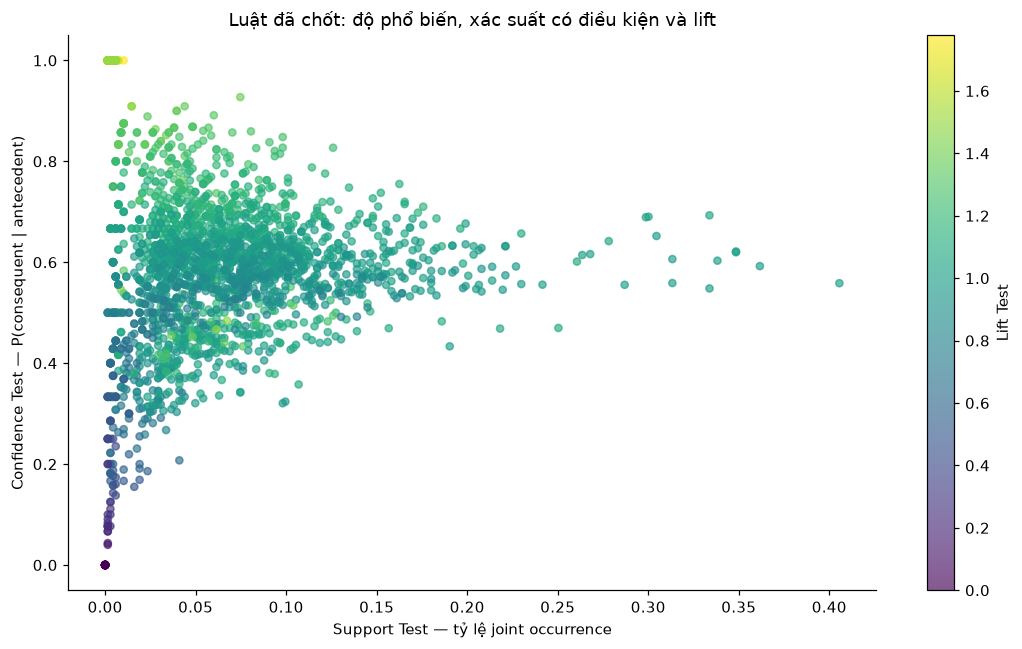

Confidence cao có thể chỉ phản ánh lớp nền phổ biến; support cao có thể đến từ điều kiện rộng.


In [4]:
print('Mỗi luật ở Test: support, confidence và lift cùng lúc:')
finite = rules.loc[rules.Test_Lift.notna() & rules.Test_Confidence.notna()]
fig, ax = plt.subplots(figsize=(10,6))
points = ax.scatter(finite.Test_Support, finite.Test_Confidence, c=finite.Test_Lift,
                    cmap='viridis', s=22, alpha=.65)
fig.colorbar(points, ax=ax, label='Lift Test')
ax.set_xlabel('Support Test — tỷ lệ joint occurrence')
ax.set_ylabel('Confidence Test — P(consequent | antecedent)')
ax.set_title('Luật đã chốt: độ phổ biến, xác suất có điều kiện và lift')
plt.tight_layout()
plt.show()
print('Confidence cao có thể chỉ phản ánh lớp nền phổ biến; support cao có thể đến từ điều kiện rộng.')

## 2. Itemset dài 1–4 item xuất hiện bao nhiêu?

Frequent itemset là tập item đồng xuất hiện đủ support trên **Train**, chưa có
vế trái/vế phải. Biểu đồ này đếm itemset ở ngưỡng support 0,02, gồm cả itemsets
không có target; không phải số luật đáng tin cậy.

Số frequent itemset theo tổng số item:


,H1,H5,H10,H20
Size,,,,
1,28,28,28,28
2,356,356,356,356
3,2683,2684,2684,2682
4,11048,11010,10993,10990


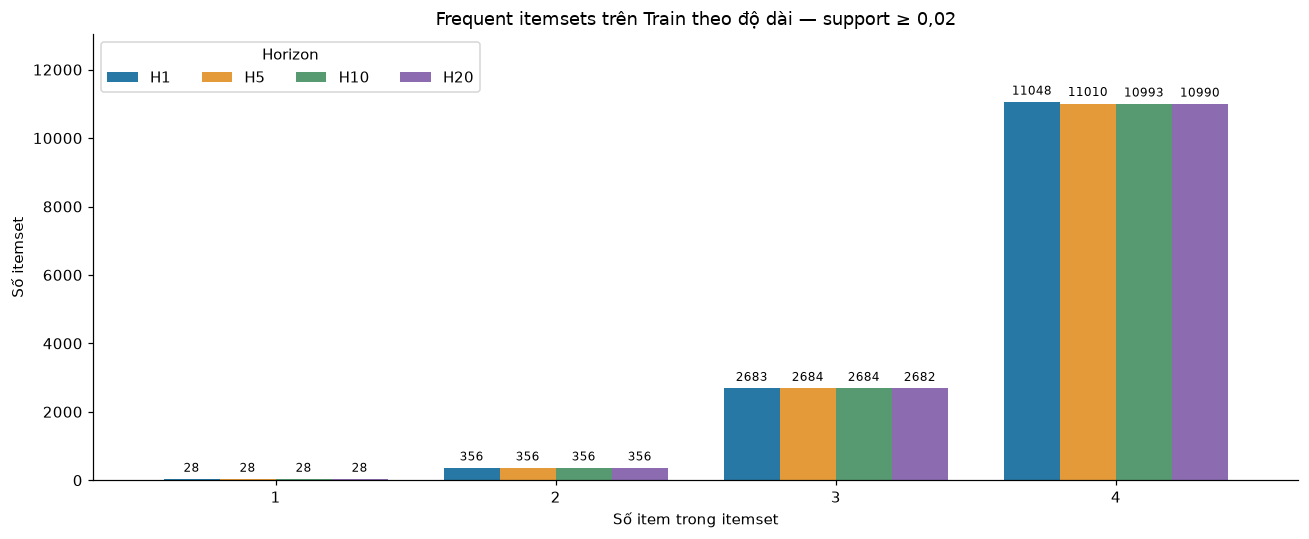

Nhận xét: itemset dài có nhiều tổ hợp khả dĩ hơn; số lượng lớn không chứng minh liên hệ mạnh hơn.


In [5]:
itemset_counts = pd.crosstab(itemsets_all.Size, itemsets_all.Horizon).reindex(
    index=[1, 2, 3, 4], columns=horizons, fill_value=0)
itemset_counts.columns = [f'H{h}' for h in horizons]
print('Số frequent itemset theo tổng số item:')
display(itemset_counts)
ax = itemset_counts.plot.bar(figsize=(12, 5), color=horizon_colors, width=0.8)
for bars in ax.containers:
    ax.bar_label(bars, fontsize=8, padding=3)
ax.set_title('Frequent itemsets trên Train theo độ dài — support ≥ 0,02')
ax.set_xlabel('Số item trong itemset')
ax.set_ylabel('Số itemset')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, itemset_counts.to_numpy().max() * 1.18)
ax.legend(title='Horizon', ncols=4)
plt.tight_layout()
plt.show()
print('Nhận xét: itemset dài có nhiều tổ hợp khả dĩ hơn; số lượng lớn không chứng minh liên hệ mạnh hơn.')

## 3. Luật đã chốt thường dài bao nhiêu?

`Length` trong nguồn là số item **antecedent**. Tổng số item của luật bằng
`Length + 1` vì consequent có đúng một target. Vì vậy luật có 2–4 item;
**1 item không đủ tạo luật** và cột tương ứng bằng 0.

Hai biểu đồ dưới cùng mô tả luật đã chốt, một theo toàn bộ luật và một theo vế trái.
Số luật không phải số phiên mà điều kiện xuất hiện.

Số luật đã chốt theo tổng số item (antecedent + consequent):


,H1,H5,H10,H20
Total_Items,,,,
1,0,0,0,0
2,12,6,6,6
3,123,65,65,70
4,700,405,371,460


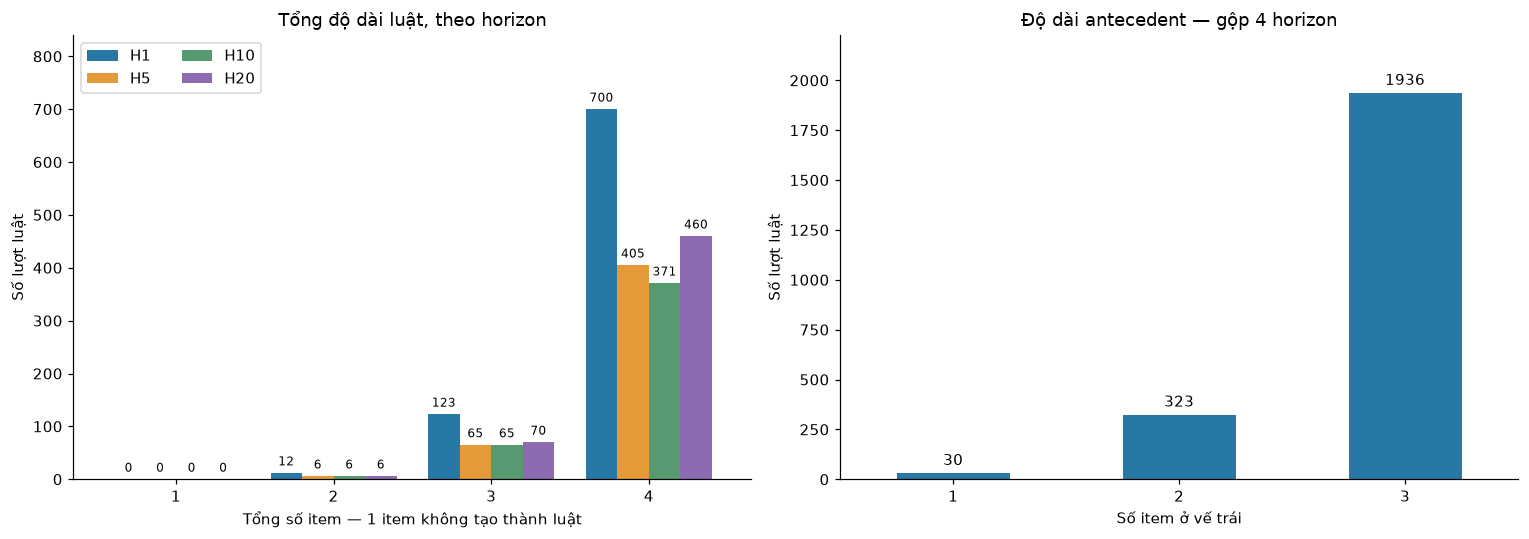

Nhận xét: 1,936/2,289 lượt luật (84.6%) có 3 item antecedent.
Luật dài cụ thể hơn nhưng có thể ít lần xuất hiện và trùng thông tin với luật khác.


In [6]:
rules['Total_Items'] = rules.Length + 1
length_counts = pd.crosstab(rules.Total_Items, rules.Horizon).reindex(
    index=[1, 2, 3, 4], columns=horizons, fill_value=0)
length_counts.columns = [f'H{h}' for h in horizons]
print('Số luật đã chốt theo tổng số item (antecedent + consequent):')
display(length_counts)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
length_counts.plot.bar(ax=axes[0], color=horizon_colors, width=0.8)
for bars in axes[0].containers:
    axes[0].bar_label(bars, fontsize=8, padding=3)
axes[0].set_title('Tổng độ dài luật, theo horizon')
axes[0].set_xlabel('Tổng số item — 1 item không tạo thành luật')
axes[0].set_ylabel('Số lượt luật')
axes[0].set_ylim(0, length_counts.to_numpy().max() * 1.2)
axes[0].legend(ncols=2)
antecedent_counts = rules.groupby('Length').size().reindex([1, 2, 3], fill_value=0)
antecedent_counts.plot.bar(ax=axes[1], color='#2878a5')
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set_title('Độ dài antecedent — gộp 4 horizon')
axes[1].set_xlabel('Số item ở vế trái')
axes[1].set_ylabel('Số lượt luật')
axes[1].set_ylim(0, antecedent_counts.max() * 1.15)
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()
longest = int(rules.Length.eq(3).sum())
print(f'Nhận xét: {longest:,}/{len(rules):,} lượt luật ({longest/len(rules):.1%}) có 3 item antecedent.')
print('Luật dài cụ thể hơn nhưng có thể ít lần xuất hiện và trùng thông tin với luật khác.')

## 4. Biểu đồ tròn: mức liên hệ còn giữ được trên Test

Chia đúng bốn nhóm đã thống nhất:

1. **Lift > 1, antecedent ≥ 30 lần:** có liên hệ dương và đủ số lần theo ngưỡng báo cáo.
2. **Lift > 1, antecedent < 30 lần:** có liên hệ dương nhưng ít quan sát.
3. **Lift ≤ 1:** không cho thấy liên hệ dương so với tỷ lệ lớp chung trên Test.
4. **Không tính được lift:** không đủ dữ liệu, chẳng hạn antecedent không xuất hiện.

Lift = confidence / tỷ lệ consequent của **chính tập Test**. Nhóm xanh không có
nghĩa “đã được chứng minh đáng tin cậy”: chưa có kiểm định thống kê. Nhóm lift ≤1
vẫn có thể chứa luật ít quan sát; cần xem thêm số lần xuất hiện trước khi kết luận.

Phân nhóm toàn bộ lượt luật đã chốt — không loại luật yếu:


,Rules,Percent
Test_Group,,
"Lift > 1, số lần ≥ 30",1042,45.52
"Lift > 1, số lần < 30",238,10.40
Lift ≤ 1,990,43.25
Không tính được lift,19,0.83


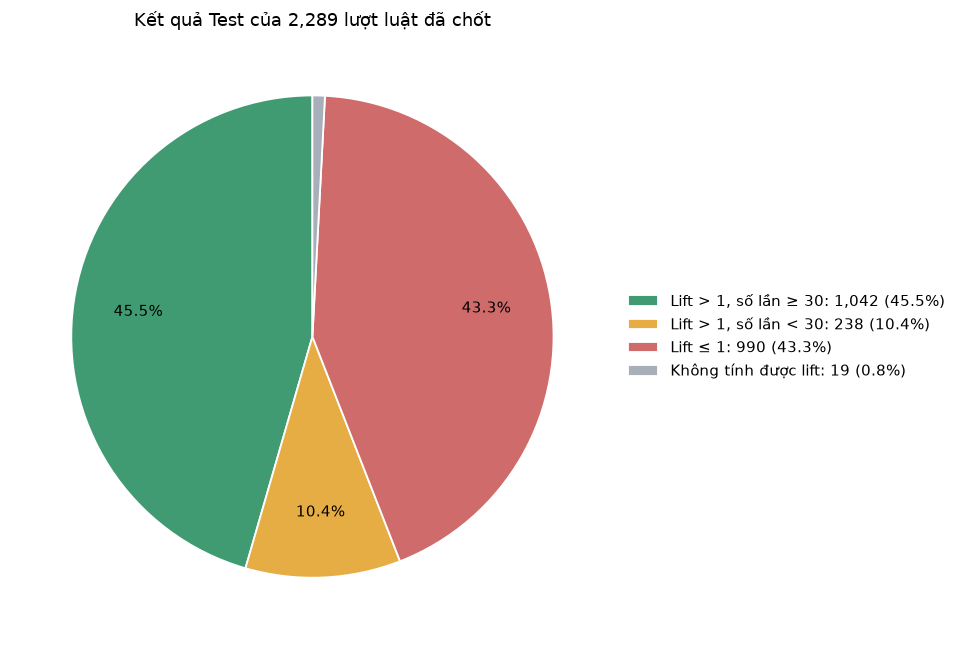

Nhận xét: 1,042/2,289 lượt luật (45.5%) có lift > 1 và antecedent ≥ 30 lần.


In [7]:
quality_labels = ['Lift > 1, số lần ≥ 30', 'Lift > 1, số lần < 30',
                  'Lift ≤ 1', 'Không tính được lift']
quality_colors = ['#409b73', '#e6ad44', '#cf6b6b', '#a8afb8']

# Phân loại từng luật theo Test, không dùng kết quả này để chọn lại luật.
rules['Test_Group'] = quality_labels[3]
valid_lift = rules.Test_Lift.notna()
positive = valid_lift & rules.Test_Lift.gt(1)
rules.loc[positive & rules.Test_Antecedent_Count.ge(30), 'Test_Group'] = quality_labels[0]
rules.loc[positive & rules.Test_Antecedent_Count.lt(30), 'Test_Group'] = quality_labels[1]
rules.loc[valid_lift & rules.Test_Lift.le(1), 'Test_Group'] = quality_labels[2]
quality_counts = rules.Test_Group.value_counts().reindex(quality_labels, fill_value=0)
quality_table = quality_counts.rename('Rules').to_frame()
quality_table['Percent'] = (quality_table.Rules / len(rules) * 100).round(2)
print('Phân nhóm toàn bộ lượt luật đã chốt — không loại luật yếu:')
display(quality_table)

fig, ax = plt.subplots(figsize=(10, 6))
wedges, _, _ = ax.pie(quality_counts, colors=quality_colors, startangle=90,
                     autopct=lambda p: f'{p:.1f}%' if p >= 2 else '',
                     pctdistance=0.73, wedgeprops={'edgecolor': 'white', 'linewidth': 1.2})
legend = [f'{name}: {count:,} ({count/len(rules):.1%})'
          for name, count in quality_counts.items()]
ax.legend(wedges, legend, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title(f'Kết quả Test của {len(rules):,} lượt luật đã chốt')
plt.tight_layout()
plt.show()
count = int(quality_counts.iloc[0])
print(f'Nhận xét: {count:,}/{len(rules):,} lượt luật ({count/len(rules):.1%}) có lift > 1 và antecedent ≥ 30 lần.')

Số luật ở từng nhóm đánh giá theo horizon:


Test_Group,"Lift > 1, số lần ≥ 30","Lift > 1, số lần < 30",Lift ≤ 1,Không tính được lift
Horizon,,,,
1,449,70,311,5
5,261,49,166,0
10,181,55,197,9
20,151,64,316,5


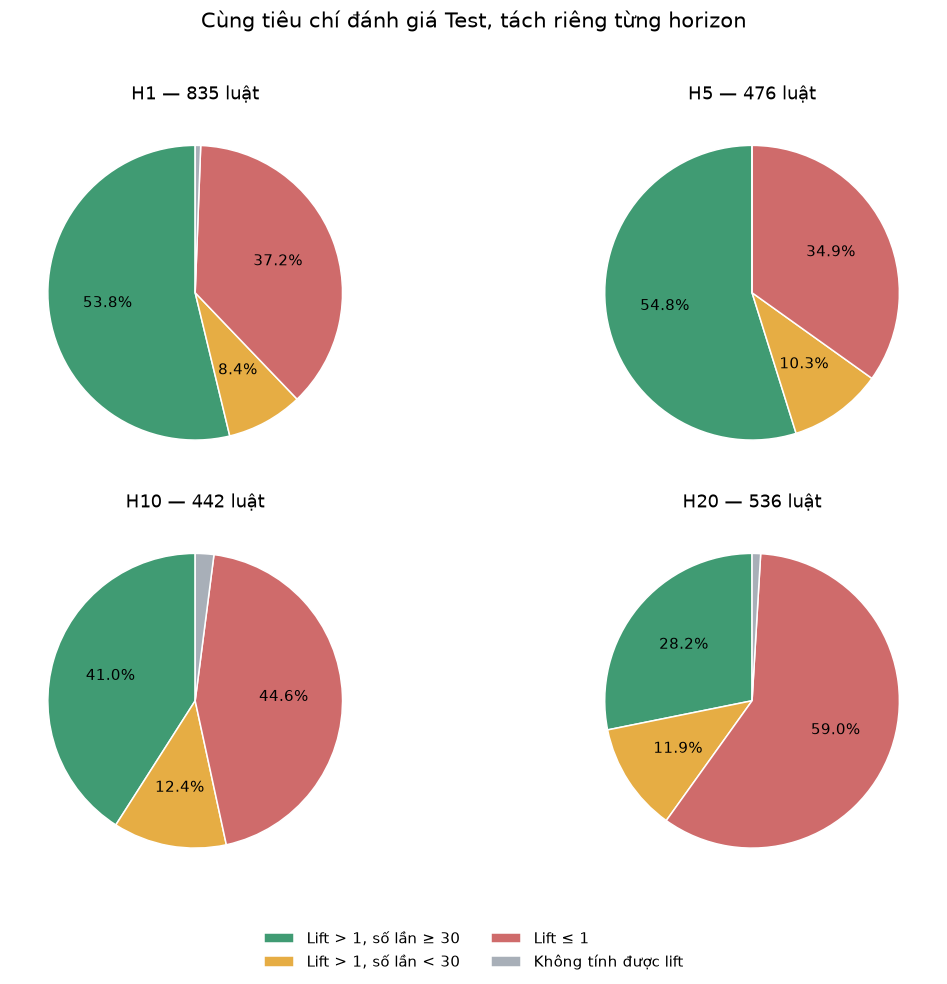

Nhận xét: tỷ lệ từng nhóm cần đọc cùng tổng số luật; mỗi horizon có một bộ luật được chọn riêng.


In [8]:
# Giữ cùng thứ tự và màu giữa các horizon để so sánh trực tiếp.
by_horizon = pd.crosstab(rules.Horizon, rules.Test_Group).reindex(
    index=horizons, columns=quality_labels, fill_value=0)
print('Số luật ở từng nhóm đánh giá theo horizon:')
display(by_horizon)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, h in zip(axes.flat, horizons):
    counts = by_horizon.loc[h]
    ax.pie(counts, colors=quality_colors, startangle=90,
           autopct=lambda p: f'{p:.1f}%' if p >= 3 else '',
           wedgeprops={'edgecolor': 'white', 'linewidth': 1})
    ax.set_title(f'H{h} — {int(counts.sum()):,} luật')
fig.legend(quality_labels, loc='lower center', ncols=2, frameon=False)
fig.suptitle('Cùng tiêu chí đánh giá Test, tách riêng từng horizon', fontsize=14)
plt.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()
print('Nhận xét: tỷ lệ từng nhóm cần đọc cùng tổng số luật; mỗi horizon có một bộ luật được chọn riêng.')

## 5. External so với Gold-only và số lần điều kiện xuất hiện

External nghĩa antecedent chứa ít nhất một item Oil, Dollar hoặc S&P 500.
Hai nhóm có số luật khác nhau nên biểu đồ dùng **tỷ lệ phần trăm**, không chỉ số lượng.
Đây là mô tả các bộ luật, chưa đo giá trị tăng thêm của external trên cùng điều kiện Gold.

Số luật theo nhóm thị trường và mức liên hệ Test:


Test_Group            Lift > 1, số lần ≥ 30  Lift > 1, số lần < 30  Lift ≤ 1  \
Horizon Market_Group                                                           
1       External                        328                     54       262   
        Gold-only                       121                     16        49   
5       External                        185                     38       143   
        Gold-only                        76                     11        23   
10      External                        125                     37       152   
        Gold-only                        56                     18        45   
20      External                        113                     42       245   
        Gold-only                        38                     22        71   

Test_Group            Không tính được lift  
Horizon Market_Group                        
1       External                         5  
        Gold-only                        0  
5       External                         0  
        Gold-only                        0  
10      External                         9  
        Gold-only                        0  
20      External                         5  
        Gold-only                        0

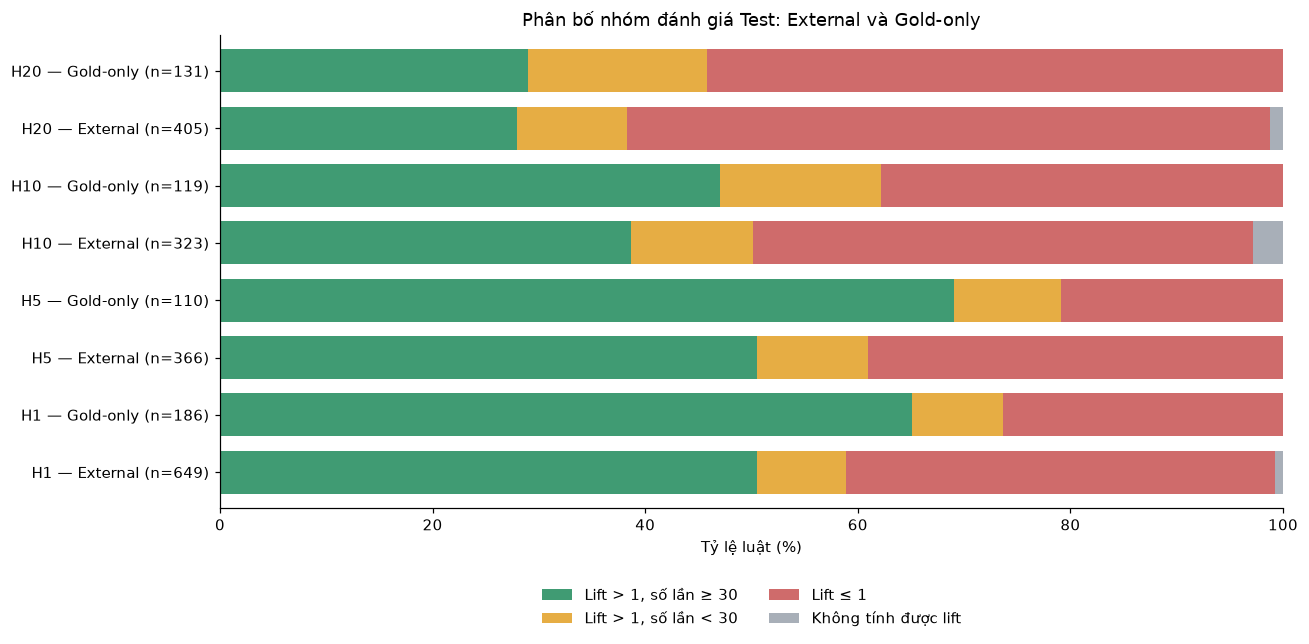

In [9]:
rules['Market_Group'] = rules.External.map({True: 'External', False: 'Gold-only'})
category_counts = pd.crosstab([rules.Horizon, rules.Market_Group], rules.Test_Group)
category_counts = category_counts.reindex(columns=quality_labels, fill_value=0)
category_pct = category_counts.div(category_counts.sum(axis=1), axis=0) * 100
print('Số luật theo nhóm thị trường và mức liên hệ Test:')
display(category_counts)
ax = category_pct.plot.barh(stacked=True, figsize=(12, 6), color=quality_colors, width=0.75)
ax.set_yticklabels([f'H{h} — {market} (n={int(category_counts.loc[(h, market)].sum())})'
                    for h, market in category_pct.index])
ax.set_title('Phân bố nhóm đánh giá Test: External và Gold-only')
ax.set_xlabel('Tỷ lệ luật (%)')
ax.set_ylabel('')
ax.set_xlim(0, 100)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

Số luật theo số lần antecedent xuất hiện trong 683 phiên Test:


,H1,H5,H10,H20
Occurrence_Bin,,,,
0–9,77,25,37,80
10–29,63,56,54,76
30–99,465,265,248,281
100–299,223,126,102,97
300–683,7,4,1,2


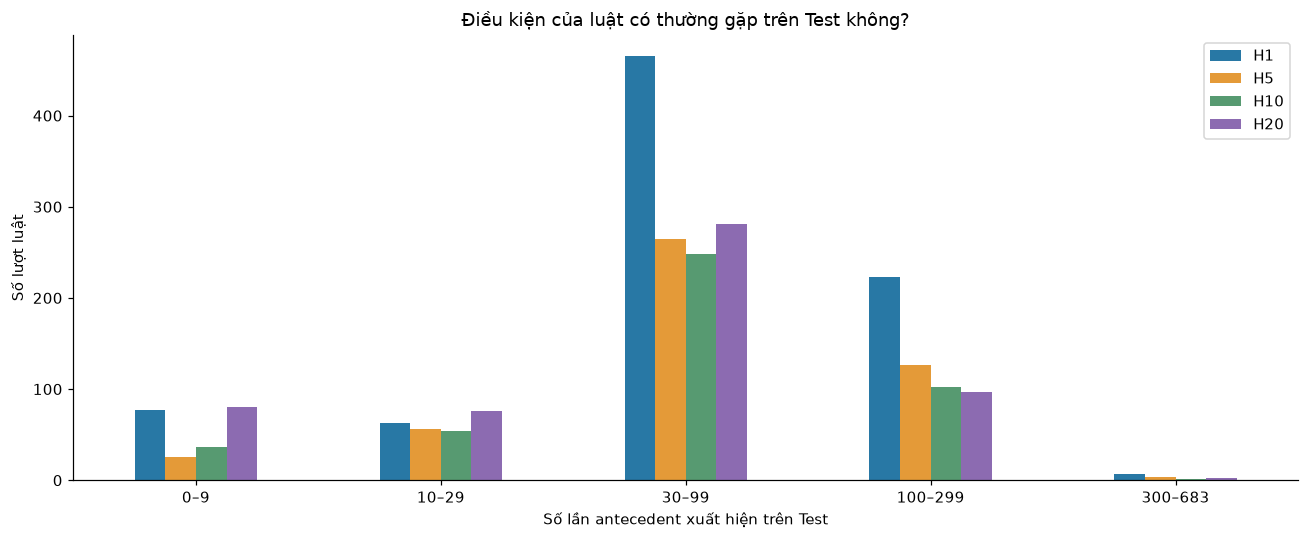

Nhận xét: lift cao khi điều kiện chỉ xuất hiện vài lần cần được đọc như bằng chứng ít quan sát.


In [10]:
# Số phiên điều kiện vế trái xảy ra khác với số luật được tìm thấy.
rules['Occurrence_Bin'] = pd.cut(rules.Test_Antecedent_Count,
                                 bins=[0, 10, 30, 100, 300, 684], right=False,
                                 labels=['0–9', '10–29', '30–99', '100–299', '300–683'])
occurrence_counts = pd.crosstab(rules.Occurrence_Bin, rules.Horizon).reindex(columns=horizons)
occurrence_counts.columns = [f'H{h}' for h in horizons]
print('Số luật theo số lần antecedent xuất hiện trong 683 phiên Test:')
display(occurrence_counts)
ax = occurrence_counts.plot.bar(figsize=(12, 5), color=horizon_colors)
ax.set_title('Điều kiện của luật có thường gặp trên Test không?')
ax.set_xlabel('Số lần antecedent xuất hiện trên Test')
ax.set_ylabel('Số lượt luật')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()
print('Nhận xét: lift cao khi điều kiện chỉ xuất hiện vài lần cần được đọc như bằng chứng ít quan sát.')

## 6. Liên hệ Up / NonUp có giữ được qua horizon?

Median lift dưới đây tính trên luật đã chốt, **không bỏ luật Test yếu**, bỏ qua NaN
khi không thể tính lift. Bao gồm cả luật ít quan sát. Bộ luật của mỗi horizon khác nhau.
Lift = 1 là mức không khác tỷ lệ lớp chung; đường tham chiếu này không phải ngưỡng
kiểm định ý nghĩa thống kê.

Tóm tắt luật external theo horizon và hướng target:


,Horizon,Direction,Rules,Median_Val_Lift,Median_Test_Lift,Test_Base_Rate,Test_Enough_And_Lift_Above_1_Count
1,1,NonUp,220,1.106799,1.027926,0.437775,118
4,1,Up,429,1.075464,1.021074,0.562225,210
7,5,NonUp,35,1.079251,0.944977,0.382138,12
10,5,Up,331,1.059458,1.036397,0.617862,173
13,10,NonUp,35,1.100230,0.952502,0.387994,12
16,10,Up,288,1.079423,1.011506,0.612006,113
19,20,NonUp,65,1.137397,0.948117,0.330893,21
22,20,Up,340,1.097981,0.956499,0.669107,92


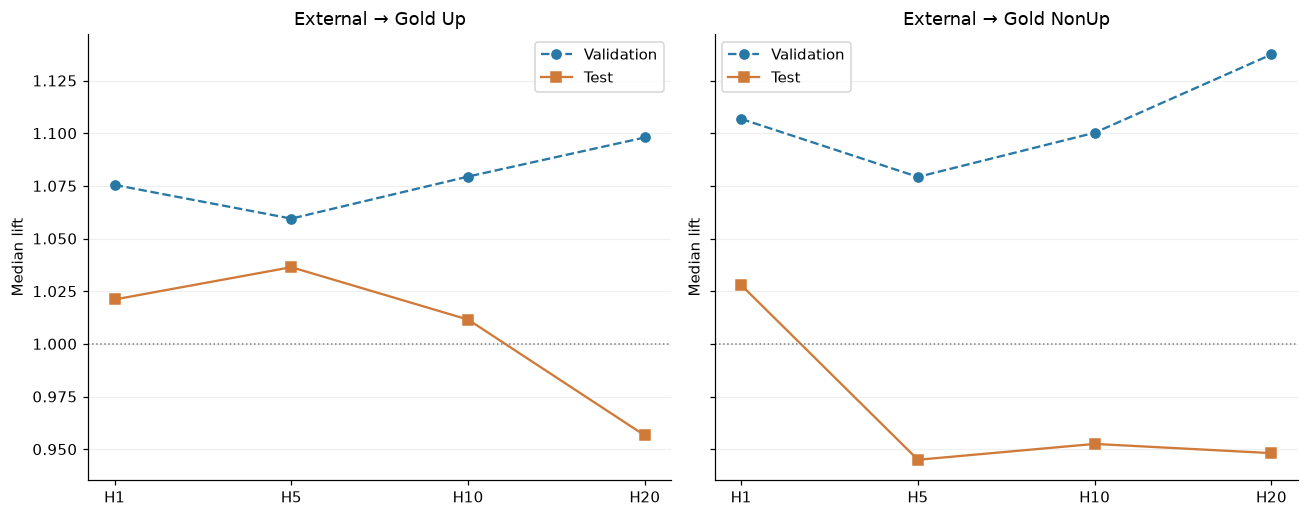

Nhận xét: Val lift > 1 là hệ quả của tiêu chí chọn luật; Test mới cho thấy mức liên hệ có giữ được hay không.


In [11]:
external_summary = summary.loc[summary.Category.eq('External')].copy()
print('Tóm tắt luật external theo horizon và hướng target:')
display(external_summary[['Horizon', 'Direction', 'Rules', 'Median_Val_Lift',
                          'Median_Test_Lift', 'Test_Base_Rate',
                          'Test_Enough_And_Lift_Above_1_Count']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, direction in zip(axes, ['Up', 'NonUp']):
    group = external_summary.loc[external_summary.Direction.eq(direction)].sort_values('Horizon')
    ax.plot(range(4), group.Median_Val_Lift, 'o--', label='Validation', color='#2878a5')
    ax.plot(range(4), group.Median_Test_Lift, 's-', label='Test', color='#cf7a38')
    ax.axhline(1, color='gray', linestyle=':', linewidth=1)
    ax.set_xticks(range(4), [f'H{h}' for h in horizons])
    ax.set_title(f'External → Gold {direction}')
    ax.set_ylabel('Median lift')
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Nhận xét: Val lift > 1 là hệ quả của tiêu chí chọn luật; Test mới cho thấy mức liên hệ có giữ được hay không.')

## 7. Cùng antecedent và hướng qua bốn horizon

Bảng này dùng `Rule_ID` (antecedent + hướng, không chứa số horizon) để phân biệt
luật xuất hiện ở nhiều bộ đã chốt. Được chọn ở nhiều horizon chưa đảm bảo lift Test
>1 ở tất cả các horizon đó. Ngưỡng quantile được fit riêng nên cùng tên item có thể
có ranh giới số khác nhẹ.

Số antecedent + hướng được chọn ở 1, 2, 3 hoặc cả 4 horizon:


,Gold-only,External
Horizons_Selected,,
1,178,638
2,78,234
3,48,127
4,17,64


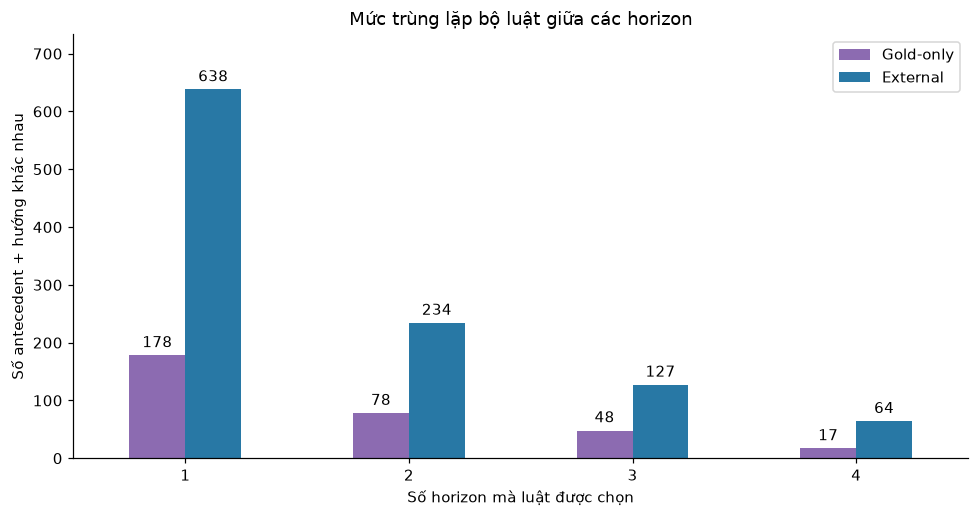

External: 64 luật được chọn ở cả 4 horizon; 10 có lift Test > 1 tại đủ cả 4.
Đây là thống kê mô tả; không dùng Test để chọn thêm một bộ luật mới.


In [12]:
selected_horizons = rules.groupby(['Rule_ID', 'External']).Horizon.nunique().reset_index(name='Horizons_Selected')
overlap = pd.crosstab(selected_horizons.Horizons_Selected, selected_horizons.External).reindex(
    index=[1, 2, 3, 4], columns=[False, True], fill_value=0)
overlap.columns = ['Gold-only', 'External']
print('Số antecedent + hướng được chọn ở 1, 2, 3 hoặc cả 4 horizon:')
display(overlap)
ax = overlap.plot.bar(figsize=(9, 4.8), color=['#8c6bb1', '#2878a5'])
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_xlabel('Số horizon mà luật được chọn')
ax.set_ylabel('Số antecedent + hướng khác nhau')
ax.set_title('Mức trùng lặp bộ luật giữa các horizon')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, overlap.to_numpy().max() * 1.15)
plt.tight_layout()
plt.show()

# Đối chiếu lift tại đủ 4 horizon, tránh xem một horizon tốt là ổn định chung.
across = rules.copy()  # Only rules selected in all four horizons are compared below.
all_four_ids = selected_horizons.loc[selected_horizons.External & selected_horizons.Horizons_Selected.eq(4), 'Rule_ID']
all_four = across.loc[across.Rule_ID.isin(all_four_ids)].copy()
stable_four = all_four.groupby('Rule_ID').Test_Lift.apply(lambda s: s.notna().all() and s.gt(1).all()).sum()
print(f'External: {len(all_four_ids)} luật được chọn ở cả 4 horizon; {int(stable_four)} có lift Test > 1 tại đủ cả 4.')
print('Đây là thống kê mô tả; không dùng Test để chọn thêm một bộ luật mới.')

## 8. Ví dụ luật — giữ thứ tự đã chọn bằng Validation

Hiển thị ba luật đầu mỗi hướng ở mỗi horizon, ưu tiên external theo thứ tự đã khóa.
Giữ cả trường hợp Test suy giảm. Số lần antecedent và joint occurrence giúp đọc
confidence/lift trong đúng bối cảnh.

In [13]:
examples = rules.loc[rules.Val_Report_Rank.le(3)].sort_values(['Horizon', 'Direction', 'Val_Report_Rank'])
example_columns = ['Val_Report_Rank', 'Antecedent', 'Consequent', 'Val_Lift',
                   'Test_Antecedent_Count', 'Test_Joint_Count', 'Test_Support',
                   'Test_Confidence', 'Test_Lift', 'Test_Group']
for h in horizons:
    print(f'H{h} — Top 3 mỗi hướng theo Validation, đối chiếu Test:')
    display(examples.loc[examples.Horizon.eq(h), example_columns])

H1 — Top 3 mỗi hướng theo Validation, đối chiếu Test:


,Val_Report_Rank,Antecedent,Consequent,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Confidence,Test_Lift,Test_Group
0,1,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_RSI_14=Medium,Gold_NonUp_H1,1.386740,66,30,0.043924,0.454545,1.038310,"Lift > 1, số lần ≥ 30"
1,2,Gold_MACD_Histogram=Positive & Gold_RSI_14=Medium & SP500_Daily_Return=Negative,Gold_NonUp_H1,1.364007,34,17,0.024890,0.500000,1.142140,"Lift > 1, số lần ≥ 30"
2,3,Gold_Distance_to_MA_20=Negative & Gold_Return_Lag_1=Positive & SP500_Daily_Return=Negative,Gold_NonUp_H1,1.326447,44,16,0.023426,0.363636,0.830648,Lift ≤ 1
287,1,Gold_RSI_14=Low & SP500_Daily_Return=Positive & SP500_Drawdown=Medium,Gold_Up_H1,1.444373,20,13,0.019034,0.650000,1.156120,"Lift > 1, số lần < 30"
288,2,Gold_Distance_to_MA_20=Negative & SP500_Daily_Return=Positive & SP500_Drawdown=Medium,Gold_Up_H1,1.375594,44,28,0.040996,0.636364,1.131866,"Lift > 1, số lần ≥ 30"
289,3,Gold_Daily_Return=Negative & Gold_Volatility_20=High & SP500_Daily_Return=Positive,Gold_Up_H1,1.366719,79,48,0.070278,0.607595,1.080696,"Lift > 1, số lần ≥ 30"


H5 — Top 3 mỗi hướng theo Validation, đối chiếu Test:


,Val_Report_Rank,Antecedent,Consequent,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Confidence,Test_Lift,Test_Group
835,1,Gold_RSI_14=Medium & Oil_Price_Change=Positive & SP500_Daily_Return=Negative,Gold_NonUp_H5,1.259126,64,31,0.045388,0.484375,1.267541,"Lift > 1, số lần ≥ 30"
836,2,Dollar_Daily_Return=Positive & Gold_RSI_14=Medium & Gold_Volatility_20=Low,Gold_NonUp_H5,1.251931,13,4,0.005857,0.307692,0.805187,Lift ≤ 1
837,3,Gold_MACD_Histogram=Negative & Gold_Volatility_20=Low & Oil_Price_Change=Positive,Gold_NonUp_H5,1.228113,21,3,0.004392,0.142857,0.373837,Lift ≤ 1
883,1,Gold_Volatility_20=High & SP500_Daily_Return=Positive & SP500_Drawdown=Shallow,Gold_Up_H5,1.442465,123,61,0.089312,0.495935,0.802663,Lift ≤ 1
884,2,Gold_Volatility_20=High & Oil_Price_Change=Positive & SP500_Daily_Return=Positive,Gold_Up_H5,1.385445,106,60,0.087848,0.566038,0.916123,Lift ≤ 1
885,3,Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=High & Oil_Price_Change=Positive,Gold_Up_H5,1.355043,88,52,0.076135,0.590909,0.956377,Lift ≤ 1


H10 — Top 3 mỗi hướng theo Validation, đối chiếu Test:


,Val_Report_Rank,Antecedent,Consequent,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Confidence,Test_Lift,Test_Group
1311,1,Dollar_Daily_Return=Negative & Gold_MACD_Histogram=Negative & SP500_Daily_Return=Negative,Gold_NonUp_H10,1.273743,61,24,0.035139,0.393443,1.014043,"Lift > 1, số lần ≥ 30"
1312,2,Gold_Distance_to_MA_20=Positive & Gold_RSI_14=Medium & SP500_Drawdown=Medium,Gold_NonUp_H10,1.254770,64,18,0.026354,0.281250,0.724882,Lift ≤ 1
1313,3,Gold_Return_Lag_1=Negative & SP500_Daily_Return=Negative & SP500_Drawdown=Shallow,Gold_NonUp_H10,1.246927,63,21,0.030747,0.333333,0.859119,Lift ≤ 1
1353,1,Gold_Daily_Return=Negative & Gold_Intraday_Range=High & SP500_Drawdown=Medium,Gold_Up_H10,1.434390,100,62,0.090776,0.620000,1.013062,"Lift > 1, số lần ≥ 30"
1354,2,Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H10,1.408529,21,18,0.026354,0.857143,1.400547,"Lift > 1, số lần < 30"
1355,3,Gold_Distance_to_MA_20=Negative & Oil_Price_Change=Negative & SP500_Drawdown=Medium,Gold_Up_H10,1.392055,45,29,0.042460,0.644444,1.053004,"Lift > 1, số lần ≥ 30"


H20 — Top 3 mỗi hướng theo Validation, đối chiếu Test:


,Val_Report_Rank,Antecedent,Consequent,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Confidence,Test_Lift,Test_Group
1753,1,Gold_RSI_14=Medium & Gold_Volatility_20=Low & SP500_Drawdown=Medium,Gold_NonUp_H20,1.482828,1,0,0.000000,0.000000,0.000000,Lift ≤ 1
1754,2,Gold_RSI_14=Medium & Gold_Volatility_20=Low & SP500_Daily_Return=Negative,Gold_NonUp_H20,1.426734,11,1,0.001464,0.090909,0.274739,Lift ≤ 1
1755,3,Gold_MACD_Histogram=Positive & Gold_RSI_14=Medium & SP500_Drawdown=Medium,Gold_NonUp_H20,1.405262,29,11,0.016105,0.379310,1.146323,"Lift > 1, số lần < 30"
1836,1,Gold_RSI_14=Low & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H20,1.756769,4,4,0.005857,1.000000,1.494530,"Lift > 1, số lần < 30"
1837,2,Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H20,1.529330,21,18,0.026354,0.857143,1.281025,"Lift > 1, số lần < 30"
1838,3,Gold_Intraday_Range=High & Gold_Volatility_20=High & SP500_Drawdown=Deep,Gold_Up_H20,1.527319,14,7,0.010249,0.500000,0.747265,Lift ≤ 1


## 9. Xếp hạng luật có liên hệ dương và đủ số lần trên Test

Theo quy ước báo cáo đã chốt, chỉ lấy luật có **lift Test > 1** và **antecedent xuất hiện ≥ 30 lần**.
Xếp **lift Test giảm dần**; nếu bằng nhau, ưu tiên số lần antecedent lớn hơn, rồi confidence cao hơn.
Hiển thị top 20 toàn bộ và top 10 của từng horizon. Biến `ranked_rules` giữ toàn bộ bảng xếp hạng
để xem thêm bằng `display(ranked_rules[ranking_columns])`.

Đây là xếp hạng mô tả **sau khi xem Test**, không phải bộ luật được chọn trước Test, không dùng
để chọn lại cấu hình hoặc tuyên bố hiệu quả trên dữ liệu chưa từng xem. Phần 8 vẫn giữ top theo
Validation để phân biệt hai cách xem. “Đáng tin” ở đây chỉ là đáp ứng quy ước lift/số quan sát,
chưa được xác nhận bằng kiểm định thống kê. Lift cao không đồng nghĩa confidence cao nhất.

In [14]:
# Chỉ xếp hạng trong bộ luật đã khóa, không khai phá thêm từ Test.
reliable_mask = rules.Test_Lift.gt(1) & rules.Test_Antecedent_Count.ge(30)
ranked_rules = rules.loc[reliable_mask].copy()
ranked_rules = ranked_rules.sort_values(
    ['Test_Lift', 'Test_Antecedent_Count', 'Test_Confidence', 'Horizon', 'Rule_ID'],
    ascending=[False, False, False, True, True], kind='stable').reset_index(drop=True)
ranked_rules.insert(0, 'Rank', range(1, len(ranked_rules) + 1))
ranked_rules['Rank_In_Horizon'] = ranked_rules.groupby('Horizon').cumcount() + 1
ranking_columns = ['Rank', 'Horizon', 'Antecedent', 'Consequent', 'Market_Group',
                   'Val_Lift', 'Test_Antecedent_Count', 'Test_Joint_Count',
                   'Test_Support', 'Test_Base_Rate', 'Test_Confidence', 'Test_Lift']
print(f'Có {len(ranked_rules):,} lượt luật đạt điều kiện. Top 20 theo lift Test giảm dần:')
# Hiện đầy đủ nội dung luật; chỉ làm tròn khi hiển thị, không đổi dữ liệu gốc.
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(ranked_rules[ranking_columns].head(20).round(4))
print('Support và confidence ở dạng tỷ lệ: 0.60 tương ứng 60%. Lift là hệ số, không phải %.')

Có 1,042 lượt luật đạt điều kiện. Top 20 theo lift Test giảm dần:


,Rank,Horizon,Antecedent,Consequent,Market_Group,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Base_Rate,Test_Confidence,Test_Lift
0,1,10,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H10,External,1.1846,30,27,0.0395,0.6120,0.9000,1.4706
1,2,20,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Oil_Price_Change=Positive,Gold_NonUp_H20,External,1.0623,95,46,0.0673,0.3309,0.4842,1.4633
2,3,10,Dollar_Daily_Return=Positive & Gold_Intraday_Range=Medium & Gold_Volatility_20=Low,Gold_Up_H10,External,1.0013,38,33,0.0483,0.6120,0.8684,1.4190
3,4,10,Gold_Intraday_Range=Medium & Gold_Return_Lag_1=Negative & Gold_Volatility_20=Low,Gold_Up_H10,Gold-only,1.1051,30,26,0.0381,0.6120,0.8667,1.4161
4,5,10,Gold_Daily_Return=Negative & Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium,Gold_Up_H10,Gold-only,1.0864,30,26,0.0381,0.6120,0.8667,1.4161
5,6,20,Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=High & SP500_Drawdown=Shallow,Gold_NonUp_H20,External,1.1698,90,42,0.0615,0.3309,0.4667,1.4103
6,7,20,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive,Gold_NonUp_H20,Gold-only,1.3649,90,42,0.0615,0.3309,0.4667,1.4103
7,8,20,Dollar_Daily_Return=Negative & Gold_MACD_Histogram=Positive & Gold_Volatility_20=Medium,Gold_Up_H20,External,1.0113,55,51,0.0747,0.6691,0.9273,1.3858
8,9,20,Gold_RSI_14=Medium & Oil_Price_Change=Positive & SP500_Drawdown=Medium,Gold_NonUp_H20,External,1.2590,55,25,0.0366,0.3309,0.4545,1.3737
9,10,20,Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive & SP500_Drawdown=Shallow,Gold_NonUp_H20,External,1.0194,73,33,0.0483,0.3309,0.4521,1.3662


Support và confidence ở dạng tỷ lệ: 0.60 tương ứng 60%. Lift là hệ số, không phải %.


In [15]:
# Tách từng horizon để bộ có nhiều luật không chiếm hết danh sách tổng hợp.
horizon_columns = ['Rank_In_Horizon', 'Antecedent', 'Consequent', 'Market_Group',
                   'Val_Lift', 'Test_Antecedent_Count', 'Test_Joint_Count',
                   'Test_Support', 'Test_Base_Rate', 'Test_Confidence', 'Test_Lift']
for h in horizons:
    local = ranked_rules.loc[ranked_rules.Horizon.eq(h)]
    print(f'H{h}: {len(local):,} luật đạt điều kiện — top 10 theo lift Test giảm dần:')
    with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
        display(local[horizon_columns].head(10).round(4))
print('Không dùng danh sách xếp hạng Test này thay cho các luật đã chốt bằng Train/Validation.')

H1: 449 luật đạt điều kiện — top 10 theo lift Test giảm dần:


,Rank_In_Horizon,Antecedent,Consequent,Market_Group,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Base_Rate,Test_Confidence,Test_Lift
11,1,Dollar_Daily_Return=Positive & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H1,External,1.0625,38,29,0.0425,0.5622,0.7632,1.3574
13,2,Gold_Daily_Return=Negative & Gold_RSI_14=High & Gold_Volatility_20=Medium,Gold_Up_H1,Gold-only,1.0271,37,28,0.0410,0.5622,0.7568,1.3460
15,3,Dollar_Daily_Return=Positive & SP500_Daily_Return=Positive & SP500_Drawdown=Medium,Gold_Up_H1,External,1.0951,49,37,0.0542,0.5622,0.7551,1.3431
20,4,Dollar_Daily_Return=Positive & Gold_Daily_Return=Negative & Gold_RSI_14=High,Gold_Up_H1,External,1.0370,57,42,0.0615,0.5622,0.7368,1.3106
22,5,Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive & SP500_Drawdown=Shallow,Gold_NonUp_H1,External,1.0401,72,41,0.0600,0.4378,0.5694,1.3008
23,6,Gold_Daily_Return=Positive & Gold_Intraday_Range=High & Gold_RSI_14=Medium,Gold_NonUp_H1,Gold-only,1.1346,88,50,0.0732,0.4378,0.5682,1.2979
37,7,Gold_Daily_Return=Positive & Gold_RSI_14=Medium & SP500_Drawdown=Shallow,Gold_NonUp_H1,External,1.1886,75,42,0.0615,0.4378,0.5600,1.2792
38,8,Gold_Daily_Return=Negative & Gold_MACD_Histogram=Positive & Gold_RSI_14=Medium,Gold_NonUp_H1,Gold-only,1.0682,50,28,0.0410,0.4378,0.5600,1.2792
39,9,Gold_MACD_Histogram=Positive & Gold_Volatility_20=Low & Oil_Price_Change=Negative,Gold_Up_H1,External,1.0833,39,28,0.0410,0.5622,0.7179,1.2770
40,10,Gold_Daily_Return=Positive & Gold_MACD_Histogram=Negative & Gold_RSI_14=Medium,Gold_NonUp_H1,Gold-only,1.0786,95,53,0.0776,0.4378,0.5579,1.2744


H5: 261 luật đạt điều kiện — top 10 theo lift Test giảm dần:


,Rank_In_Horizon,Antecedent,Consequent,Market_Group,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Base_Rate,Test_Confidence,Test_Lift
12,1,Gold_Distance_to_MA_20=Positive & Gold_MACD_Histogram=Positive & Gold_Volatility_20=High,Gold_NonUp_H5,Gold-only,1.0003,138,71,0.1040,0.3821,0.5145,1.3464
16,2,Gold_MACD_Histogram=Positive & Oil_Price_Change=Negative & SP500_Drawdown=Medium,Gold_NonUp_H5,External,1.0377,45,23,0.0337,0.3821,0.5111,1.3375
29,3,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H5,External,1.1063,30,24,0.0351,0.6179,0.8000,1.2948
30,4,Gold_Daily_Return=Negative & Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium,Gold_Up_H5,Gold-only,1.0502,30,24,0.0351,0.6179,0.8000,1.2948
31,5,Gold_Distance_to_MA_20=Positive & Gold_Intraday_Range=High & Gold_Volatility_20=High,Gold_NonUp_H5,Gold-only,1.1668,174,86,0.1259,0.3821,0.4943,1.2934
32,6,Dollar_Daily_Return=Positive & Gold_Intraday_Range=Medium & Gold_MACD_Histogram=Negative,Gold_Up_H5,External,1.0852,39,31,0.0454,0.6179,0.7949,1.2865
34,7,Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive & Gold_Volatility_20=Medium,Gold_Up_H5,Gold-only,1.0801,34,27,0.0395,0.6179,0.7941,1.2853
44,8,Gold_RSI_14=Medium & Oil_Price_Change=Positive & SP500_Daily_Return=Negative,Gold_NonUp_H5,External,1.2591,64,31,0.0454,0.3821,0.4844,1.2675
48,9,Dollar_Daily_Return=Positive & Gold_RSI_14=Low & SP500_Drawdown=Medium,Gold_Up_H5,External,1.1924,32,25,0.0366,0.6179,0.7812,1.2644
52,10,Gold_MACD_Histogram=Negative & Gold_Volatility_20=Medium & SP500_Daily_Return=Negative,Gold_Up_H5,External,1.0163,36,28,0.0410,0.6179,0.7778,1.2588


H10: 181 luật đạt điều kiện — top 10 theo lift Test giảm dần:


,Rank_In_Horizon,Antecedent,Consequent,Market_Group,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Base_Rate,Test_Confidence,Test_Lift
0,1,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H10,External,1.1846,30,27,0.0395,0.612,0.9000,1.4706
2,2,Dollar_Daily_Return=Positive & Gold_Intraday_Range=Medium & Gold_Volatility_20=Low,Gold_Up_H10,External,1.0013,38,33,0.0483,0.612,0.8684,1.4190
3,3,Gold_Intraday_Range=Medium & Gold_Return_Lag_1=Negative & Gold_Volatility_20=Low,Gold_Up_H10,Gold-only,1.1051,30,26,0.0381,0.612,0.8667,1.4161
4,4,Gold_Daily_Return=Negative & Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium,Gold_Up_H10,Gold-only,1.0864,30,26,0.0381,0.612,0.8667,1.4161
19,5,Gold_Intraday_Range=Medium & Gold_Volatility_20=Low & SP500_Daily_Return=Positive,Gold_Up_H10,External,1.1147,37,30,0.0439,0.612,0.8108,1.3248
26,6,Gold_Intraday_Range=Medium & Gold_Volatility_20=Low,Gold_Up_H10,Gold-only,1.0096,68,54,0.0791,0.612,0.7941,1.2976
47,7,Gold_Intraday_Range=Medium & Gold_Volatility_20=Low & Oil_Price_Change=Negative,Gold_Up_H10,External,1.0454,31,24,0.0351,0.612,0.7742,1.2650
62,8,Gold_Distance_to_MA_20=Positive & Gold_Intraday_Range=High & Gold_Volatility_20=High,Gold_NonUp_H10,Gold-only,1.0391,174,84,0.1230,0.388,0.4828,1.2442
63,9,Gold_MACD_Histogram=Positive & Gold_RSI_14=High & Gold_Volatility_20=High,Gold_NonUp_H10,Gold-only,1.0706,83,40,0.0586,0.388,0.4819,1.2421
70,10,Gold_Distance_to_MA_20=Negative & Gold_RSI_14=Medium & Gold_Volatility_20=Medium,Gold_Up_H10,Gold-only,1.2266,37,28,0.0410,0.612,0.7568,1.2365


H20: 151 luật đạt điều kiện — top 10 theo lift Test giảm dần:


,Rank_In_Horizon,Antecedent,Consequent,Market_Group,Val_Lift,Test_Antecedent_Count,Test_Joint_Count,Test_Support,Test_Base_Rate,Test_Confidence,Test_Lift
1,1,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Oil_Price_Change=Positive,Gold_NonUp_H20,External,1.0623,95,46,0.0673,0.3309,0.4842,1.4633
5,2,Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=High & SP500_Drawdown=Shallow,Gold_NonUp_H20,External,1.1698,90,42,0.0615,0.3309,0.4667,1.4103
6,3,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive,Gold_NonUp_H20,Gold-only,1.3649,90,42,0.0615,0.3309,0.4667,1.4103
7,4,Dollar_Daily_Return=Negative & Gold_MACD_Histogram=Positive & Gold_Volatility_20=Medium,Gold_Up_H20,External,1.0113,55,51,0.0747,0.6691,0.9273,1.3858
8,5,Gold_RSI_14=Medium & Oil_Price_Change=Positive & SP500_Drawdown=Medium,Gold_NonUp_H20,External,1.2590,55,25,0.0366,0.3309,0.4545,1.3737
9,6,Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive & SP500_Drawdown=Shallow,Gold_NonUp_H20,External,1.0194,73,33,0.0483,0.3309,0.4521,1.3662
10,7,Gold_Daily_Return=Negative & Gold_Intraday_Range=Medium & Oil_Price_Change=Negative,Gold_Up_H20,External,1.2464,33,30,0.0439,0.6691,0.9091,1.3587
14,8,Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium & Gold_Return_Lag_1=Negative,Gold_Up_H20,Gold-only,1.0208,30,27,0.0395,0.6691,0.9000,1.3451
17,9,Gold_Intraday_Range=High & Gold_RSI_14=Medium & SP500_Daily_Return=Positive,Gold_NonUp_H20,External,1.0827,102,45,0.0659,0.3309,0.4412,1.3333
18,10,Gold_Volatility_20=Medium & Oil_Price_Change=Negative & SP500_Daily_Return=Negative,Gold_Up_H20,External,1.0221,46,41,0.0600,0.6691,0.8913,1.3321


Không dùng danh sách xếp hạng Test này thay cho các luật đã chốt bằng Train/Validation.


## Xếp hạng bổ sung theo từng góc nhìn

Dùng cùng nhóm hậu kiểm đã chốt: lift Test >1 và antecedent ≥30 lần. Ba bảng **độc lập**
xếp theo lift, confidence hoặc support, không ghép thành điểm tổng hợp tùy ý. Hiển thị
đủ ba chỉ số cùng base rate và số quan sát để đọc trade-off. Toàn bộ luật vẫn ở các bảng trên.

In [16]:
eligible = rules.loc[rules.Test_Lift.gt(1) & rules.Test_Antecedent_Count.ge(30)].copy()
columns = ['Horizon','Antecedent','Consequent','Test_Antecedent_Count','Test_Joint_Count',
           'Train_Support','Train_Confidence','Train_Lift',
           'Val_Support','Val_Confidence','Val_Lift',
           'Test_Support','Test_Confidence','Test_Lift','Test_Base_Rate']
for metric in ['Lift','Confidence','Support']:
    ordered = eligible.sort_values([f'Test_{metric}','Test_Antecedent_Count','Rule_ID'],
                                   ascending=[False,False,True],kind='stable')
    print(f'Top 10 theo {metric} Test giảm dần — cùng điều kiện hậu kiểm:')
    with pd.option_context('display.max_colwidth',None,'display.max_columns',None):
        display(ordered[columns].head(10).round(4))
print('Ba thứ tự trả lời ba câu hỏi khác nhau; không gọi đây là cấu hình được chọn trước Test.')

Top 10 theo Lift Test giảm dần — cùng điều kiện hậu kiểm:


,Horizon,Antecedent,Consequent,Test_Antecedent_Count,Test_Joint_Count,Train_Support,Train_Confidence,Train_Lift,Val_Support,Val_Confidence,Val_Lift,Test_Support,Test_Confidence,Test_Lift,Test_Base_Rate
1398,10,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H10,30,27,0.0411,0.5612,1.0085,0.0793,0.6146,1.1846,0.0395,0.9000,1.4706,0.6120
1799,20,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Oil_Price_Change=Positive,Gold_NonUp_H20,95,46,0.0275,0.5140,1.1496,0.0368,0.5094,1.0623,0.0673,0.4842,1.4633,0.3309
1639,10,Dollar_Daily_Return=Positive & Gold_Intraday_Range=Medium & Gold_Volatility_20=Low,Gold_Up_H10,38,33,0.0349,0.5645,1.0145,0.0538,0.5195,1.0013,0.0483,0.8684,1.4190,0.6120
1678,10,Gold_Intraday_Range=Medium & Gold_Return_Lag_1=Negative & Gold_Volatility_20=Low,Gold_Up_H10,30,26,0.0322,0.5917,1.0634,0.0578,0.5733,1.1051,0.0381,0.8667,1.4161,0.6120
1685,10,Gold_Daily_Return=Negative & Gold_Distance_to_MA_20=Negative & Gold_Volatility_20=Medium,Gold_Up_H10,30,26,0.0531,0.6265,1.1258,0.0833,0.5636,1.0864,0.0381,0.8667,1.4161,0.6120
1777,20,Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=High & SP500_Drawdown=Shallow,Gold_NonUp_H20,90,42,0.0205,0.5125,1.1462,0.0313,0.5610,1.1698,0.0615,0.4667,1.4103,0.3309
1818,20,Gold_Intraday_Range=High & Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive,Gold_NonUp_H20,90,42,0.0257,0.5099,1.1404,0.0490,0.6545,1.3649,0.0615,0.4667,1.4103,0.3309
2150,20,Dollar_Daily_Return=Negative & Gold_MACD_Histogram=Positive & Gold_Volatility_20=Medium,Gold_Up_H20,55,51,0.0497,0.5735,1.0373,0.0817,0.5263,1.0113,0.0747,0.9273,1.3858,0.6691
1765,20,Gold_RSI_14=Medium & Oil_Price_Change=Positive & SP500_Drawdown=Medium,Gold_NonUp_H20,55,25,0.0315,0.5250,1.1741,0.0436,0.6038,1.2590,0.0366,0.4545,1.3737,0.3309
1809,20,Gold_RSI_14=Medium & Gold_Return_Lag_1=Positive & SP500_Drawdown=Shallow,Gold_NonUp_H20,73,33,0.0277,0.5092,1.1387,0.0300,0.4889,1.0194,0.0483,0.4521,1.3662,0.3309


Top 10 theo Confidence Test giảm dần — cùng điều kiện hậu kiểm:


,Horizon,Antecedent,Consequent,Test_Antecedent_Count,Test_Joint_Count,Train_Support,Train_Confidence,Train_Lift,Val_Support,Val_Confidence,Val_Lift,Test_Support,Test_Confidence,Test_Lift,Test_Base_Rate
2150,20,Dollar_Daily_Return=Negative & Gold_MACD_Histogram=Positive & Gold_Volatility_20=Medium,Gold_Up_H20,55,51,0.0497,0.5735,1.0373,0.0817,0.5263,1.0113,0.0747,0.9273,1.3858,0.6691
1878,20,Gold_Daily_Return=Negative & Gold_Intraday_Range=Medium & Oil_Price_Change=Negative,Gold_Up_H20,33,30,0.0475,0.5605,1.0138,0.0654,0.6486,1.2464,0.0439,0.9091,1.3587,0.6691
1398,10,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H10,30,27,0.0411,0.5612,1.0085,0.0793,0.6146,1.1846,0.0395,0.9000,1.4706,0.6120
2266,20,Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium & Gold_Return_Lag_1=Negative,Gold_Up_H20,30,27,0.0492,0.5661,1.0239,0.0695,0.5312,1.0208,0.0395,0.9000,1.3451,0.6691
2132,20,Gold_Volatility_20=Medium & Oil_Price_Change=Negative & SP500_Daily_Return=Negative,Gold_Up_H20,46,41,0.0505,0.5739,1.0380,0.0681,0.5319,1.0221,0.0600,0.8913,1.3321,0.6691
1848,20,Gold_Return_Lag_1=Negative & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H20,38,33,0.0340,0.5574,1.0082,0.0409,0.7500,1.4411,0.0483,0.8684,1.2979,0.6691
1639,10,Dollar_Daily_Return=Positive & Gold_Intraday_Range=Medium & Gold_Volatility_20=Low,Gold_Up_H10,38,33,0.0349,0.5645,1.0145,0.0538,0.5195,1.0013,0.0483,0.8684,1.4190,0.6120
1844,20,Gold_Daily_Return=Negative & Gold_Volatility_20=Medium & SP500_Drawdown=Medium,Gold_Up_H20,38,33,0.0370,0.5827,1.0539,0.0436,0.7619,1.4640,0.0483,0.8684,1.2979,0.6691
2154,20,Gold_Return_Lag_1=Negative & Gold_Volatility_20=Medium & Oil_Price_Change=Negative,Gold_Up_H20,45,39,0.0445,0.6014,1.0877,0.0572,0.5250,1.0088,0.0571,0.8667,1.2953,0.6691
1935,20,Dollar_Daily_Return=Positive & Gold_Distance_to_MA_20=Negative & Gold_Intraday_Range=Medium,Gold_Up_H20,30,26,0.0407,0.5544,1.0028,0.0790,0.6042,1.1609,0.0381,0.8667,1.2953,0.6691


Top 10 theo Support Test giảm dần — cùng điều kiện hậu kiểm:


,Horizon,Antecedent,Consequent,Test_Antecedent_Count,Test_Joint_Count,Train_Support,Train_Confidence,Train_Lift,Val_Support,Val_Confidence,Val_Lift,Test_Support,Test_Confidence,Test_Lift,Test_Base_Rate
1295,5,Gold_Return_Lag_1=Positive,Gold_Up_H5,384,238,0.2936,0.5620,1.0184,0.2817,0.5424,1.0106,0.3485,0.6198,1.0031,0.6179
1110,5,SP500_Daily_Return=Positive,Gold_Up_H5,383,238,0.3063,0.5583,1.0118,0.2844,0.5532,1.0308,0.3485,0.6214,1.0057,0.6179
2043,20,Oil_Price_Change=Negative,Gold_Up_H20,329,228,0.2692,0.5606,1.0141,0.2439,0.5559,1.0681,0.3338,0.6930,1.0357,0.6691
2271,20,Gold_Return_Lag_1=Negative,Gold_Up_H20,297,205,0.2654,0.5625,1.0174,0.2507,0.5303,1.0189,0.3001,0.6902,1.0316,0.6691
2257,20,Gold_Daily_Return=Negative,Gold_Up_H20,296,204,0.2639,0.5593,1.0117,0.2575,0.5431,1.0436,0.2987,0.6892,1.0300,0.6691
1722,10,Gold_Daily_Return=Negative,Gold_Up_H10,296,190,0.2633,0.5581,1.0030,0.2554,0.5367,1.0345,0.2782,0.6419,1.0488,0.6120
1741,10,Gold_Return_Lag_1=Negative,Gold_Up_H10,297,183,0.2648,0.5613,1.0087,0.2500,0.5254,1.0127,0.2679,0.6162,1.0068,0.6120
811,1,Gold_Daily_Return=Negative,Gold_Up_H1,296,178,0.2572,0.5454,1.0430,0.2510,0.5294,1.0196,0.2606,0.6014,1.0696,0.5622
279,1,Gold_Volatility_20=High,Gold_NonUp_H1,364,171,0.1667,0.5000,1.0480,0.0863,0.4962,1.0321,0.2504,0.4698,1.0731,0.4378
1285,5,Gold_Distance_to_MA_20=Negative,Gold_Up_H5,239,157,0.2490,0.5534,1.0029,0.2657,0.5467,1.0186,0.2299,0.6569,1.0632,0.6179


Ba thứ tự trả lời ba câu hỏi khác nhau; không gọi đây là cấu hình được chọn trước Test.


## 10. Tổng hợp cách diễn giải

- **Số luật:** bộ luật lớn hơn không tự động tốt hơn. Luật dài có nhiều tổ hợp và
  nhiều luật có thể cùng đúng trên một phiên.
- **Mức liên hệ:** lift >1 cho biết confidence cao hơn tỷ lệ target chung, không
  đồng nghĩa dự đoán đúng trên 50%, có ý nghĩa thống kê hoặc có lợi nhuận giao dịch.
- **Số quan sát:** luôn đọc lift cùng số lần antecedent xuất hiện. Ngưỡng 30 là quy
  ước báo cáo đã chốt, không phải bảo đảm về độ tin cậy thống kê.
- **Qua horizon:** phải xem cả Up và NonUp, cả Val và Test. Các nhóm luật ở mỗi
  horizon khác nhau; bảng cùng Rule_ID hỗ trợ đối chiếu cùng antecedent/hướng.
- **External:** kết quả bổ sung góc nhìn về liên hệ cross-market, nhưng không chứng
  minh nguyên nhân Model B không cải thiện nhất quán hoặc giá trị tăng thêm của
  external so với Gold-only.
- **Giới hạn:** horizon chồng lấn, ngưỡng encoding riêng, nhiều luật gần giống nhau,
  chưa có kiểm định nhiều giả thuyết hoặc kiểm định lợi nhuận.

Đọc thêm `results/arm/BAO_CAO_ARM.md`. Phần biểu đồ chỉ tổng hợp kết quả đã khóa trong arm_test.ipynb; không chọn lại luật bằng Test.